# Як рибальський тиск впливає на запас і вилов?

**Питання:** як кількість рибалок та інтенсивність вилову (`catch-rate`) впливають
на запас риби й обсяг вилову за фіксованого природного відновлення?

Порівнюємо кінцевий стан на **tick 500**: 77 комбінацій, по 20 повторів.
Вилов — **за останній такт**, усереднений між повторами.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

DATA_PATH = Path('../experiments/2/table.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('/Users/igor/projects/phd/modeling-course/experiments/2/table.csv')
with DATA_PATH.open(encoding='utf-8-sig', newline='') as handle:
    header = next(i for i, row in enumerate(csv.reader(handle)) if '[run number]' in row)
raw = pd.read_csv(DATA_PATH, skiprows=header)
df = raw.rename(columns={'[run number]':'run', '[step]':'tick',
    'number-of-fishers':'fishers', 'catch-rate':'catch_rate',
    'total-fish / (count patches * max-fish-stock)':'stock',
    'catch-per-tick':'catch', 'catch-per-fisher':'per_fisher'})
assert len(df)==1540 and df.run.nunique()==1540 and df.tick.eq(500).all()
assert not df[['fishers','catch_rate','stock','catch','per_fisher']].isna().any().any()
assert df.groupby(['fishers','catch_rate']).size().eq(20).all()
summary = df.groupby(['fishers','catch_rate'])[['stock','catch','per_fisher']].mean()
assert len(summary)==77
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
    'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120})

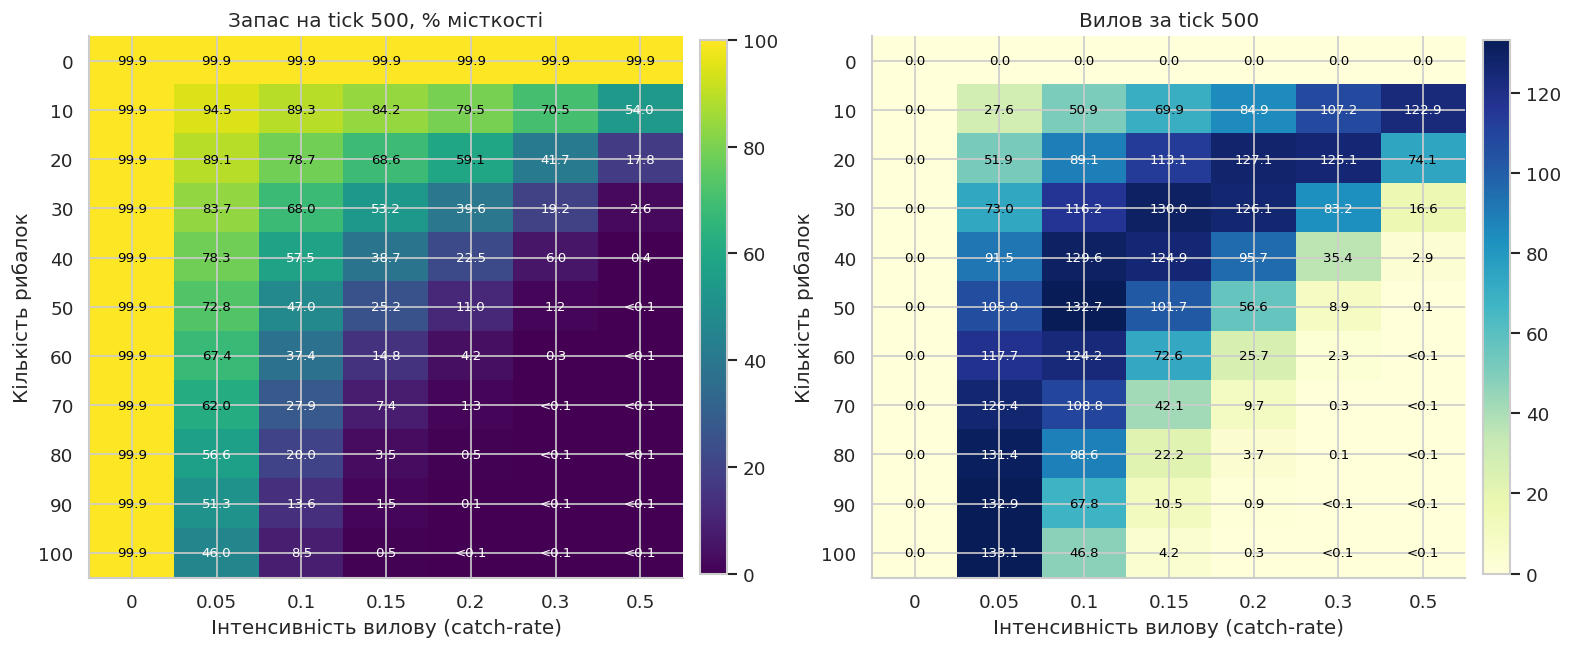

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), constrained_layout=True)
for ax, metric, title, scale, cmap, vmax in [
    (axes[0], 'stock', 'Запас на tick 500, % місткості', 100, 'viridis', 100),
    (axes[1], 'catch', 'Вилов за tick 500', 1, 'YlGnBu', None),
]:
    grid = summary[metric].unstack('catch_rate').sort_index()
    values = grid.to_numpy()*scale
    im = ax.imshow(values, aspect='auto', cmap=cmap, vmin=0, vmax=vmax)
    ax.set_xticks(range(len(grid.columns)), [f'{v:g}' for v in grid.columns])
    ax.set_yticks(range(len(grid.index)), [str(v) for v in grid.index])
    ax.set(xlabel='Інтенсивність вилову (catch-rate)', ylabel='Кількість рибалок', title=title)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i,j]
            rgba = im.cmap(im.norm(value))
            luminance = .2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
            label = '<0.1' if 0 < value < .05 else f'{value:.1f}'
            ax.text(j,i,label,ha='center',va='center',fontsize=8,
                    color='black' if luminance>.52 else 'white')
    plt.colorbar(im, ax=ax, fraction=.045, pad=.03)
plt.show()

## Як змінюється ефект кількості рибалок за різних лімітів

Точки — середні результати на **tick 500**; вертикальні відрізки — **95% bootstrap-інтервали
середніх між 20 повторами**. Менший `catch-rate` означає суворіший ліміт у цій моделі.
Нуль рибалок або `catch-rate = 0` — контроль без вилову.

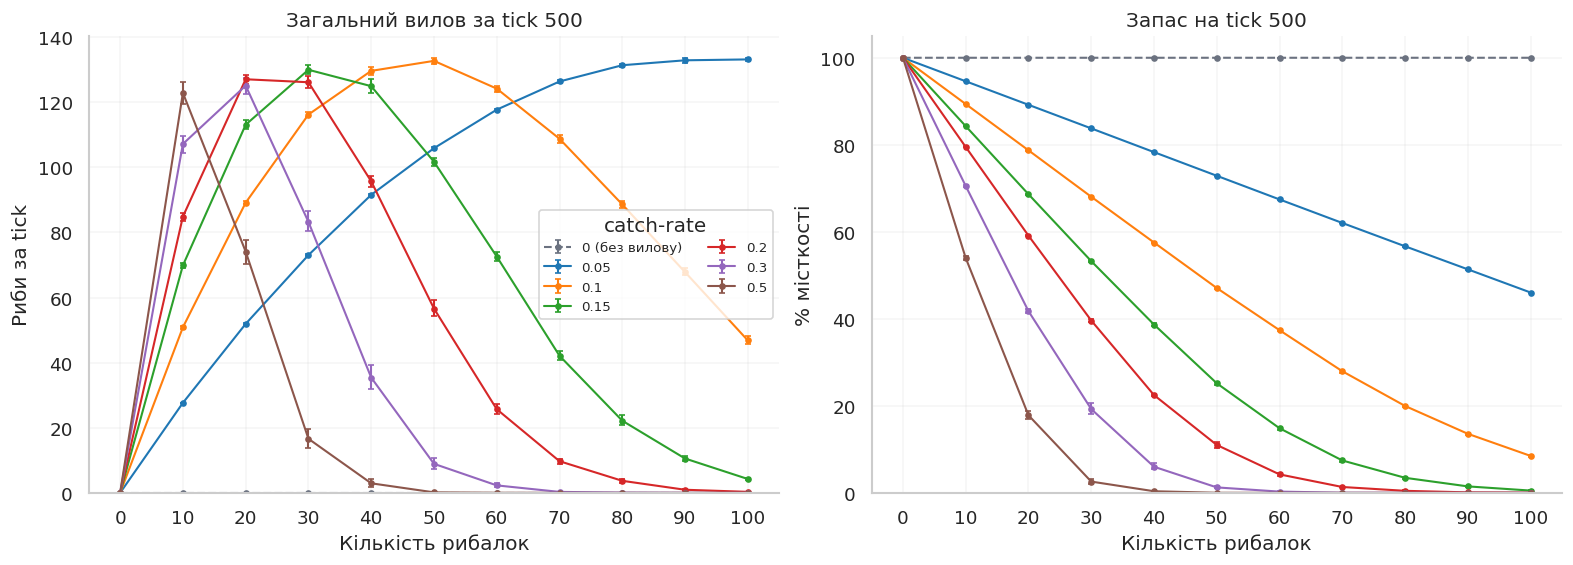

In [3]:
rng = np.random.default_rng(20261021)
records = []
for (fishers, rate), group in df.groupby(['fishers','catch_rate'], sort=True):
    values = group[['stock','catch']].to_numpy()
    indices = rng.integers(0, len(group), size=(3000, len(group)))
    boot_means = values[indices].mean(axis=1)
    limits = np.quantile(boot_means, [.025,.975], axis=0)
    records.append({'fishers':fishers, 'catch_rate':rate,
        'stock':values[:,0].mean(), 'stock_lo':limits[0,0], 'stock_hi':limits[1,0],
        'catch':values[:,1].mean(), 'catch_lo':limits[0,1], 'catch_hi':limits[1,1]})
intervals = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
rates = sorted(intervals.loc[intervals.catch_rate>0,'catch_rate'].unique())
for i, rate in enumerate([0] + rates):
    part = intervals[np.isclose(intervals.catch_rate, rate)].sort_values('fishers')
    color = '#6b7280' if rate==0 else plt.get_cmap('tab10')(i-1)
    label = '0 (без вилову)' if rate==0 else f'{rate:g}'
    for ax, metric, scale in [(axes[0],'catch',1), (axes[1],'stock',100)]:
        y = part[metric].to_numpy()*scale
        errors = np.maximum(np.vstack([
            y-part[metric+'_lo'].to_numpy()*scale,
            part[metric+'_hi'].to_numpy()*scale-y]), 0)
        ax.errorbar(part.fishers, y, yerr=errors, marker='o', ms=3, capsize=2,
            lw=1.25, ls='--' if rate==0 else '-', color=color, label=label)
for ax in axes:
    ax.set_xlabel('Кількість рибалок')
    ax.set_xticks(sorted(intervals.fishers.unique()))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.18)
axes[0].set(title='Загальний вилов за tick 500', ylabel='Риби за tick')
axes[1].set(title='Запас на tick 500', ylabel='% місткості')
axes[0].legend(title='catch-rate', ncols=2, fontsize=8)
plt.show()

**За вищої інтенсивності спад вилову починається за меншої кількості рибалок.**
Серед перевірених значень за `catch-rate = 0.1` найбільший середній вилов маємо за **50 рибалок**,
а за `catch-rate = 0.2` — за **20**. Отже, один ліміт не дає однакового результату за різної кількості учасників.

## Відповідь на дослідницьке питання

**Запас зменшується зі зростанням кількості рибалок та інтенсивності вилову.
Вилов спочатку зростає, але за надмірного тиску падає разом із запасом.**

- За `catch-rate = 0.15`: збільшення кількості рибалок із **30 до 100** знижує запас
  із **53.2% до 0.5%**, а вилов — із **130.0 до 4.2**.
- Для **50 рибалок**: підвищення `catch-rate` із **0.1 до 0.2** знижує запас
  із **47.0% до 11.0%**, а вилов — із **132.7 до 56.6**.

Отже, допустиму інтенсивність вилову потрібно узгоджувати з кількістю рибалок.

## Близький вилов за різної кількості рибалок

Беремо два сценарії й усереднюємо їхні **20 повторів на tick 500**.
Відсоткову різницю вилову рахуємо відносно сценарію зі 100 рибалками.
Нижче — розрахунки без округлення проміжних значень; у висновку числа округлені.

In [4]:
n_a, rate_a = 30, 0.15
n_b, rate_b = 100, 0.05
scenario_a = df[(df.fishers == n_a) & np.isclose(df.catch_rate, rate_a)]
scenario_b = df[(df.fishers == n_b) & np.isclose(df.catch_rate, rate_b)]
assert len(scenario_a) == len(scenario_b) == 20

# Середній вилов останнього такту між повторами: сума / кількість повторів.
catch_a = scenario_a['catch'].sum() / len(scenario_a)
catch_b = scenario_b['catch'].sum() / len(scenario_b)
# У CSV stock — частка місткості. Перетворюємо середню частку на відсотки.
stock_a_pct = 100 * scenario_a['stock'].mean()
stock_b_pct = 100 * scenario_b['stock'].mean()

catch_less_pct = 100 * (catch_b - catch_a) / catch_b
per_fisher_a = catch_a / n_a
per_fisher_b = catch_b / n_b
productivity_ratio = per_fisher_a / per_fisher_b
stock_difference_pp = stock_a_pct - stock_b_pct
assert np.isclose(per_fisher_a, scenario_a['per_fisher'].mean())
assert np.isclose(per_fisher_b, scenario_b['per_fisher'].mean())

print(f'A: {n_a} рибалок, c={rate_a}; вилов = {catch_a:.4f}; запас = {stock_a_pct:.4f}%')
print(f'B: {n_b} рибалок, c={rate_b}; вилов = {catch_b:.4f}; запас = {stock_b_pct:.4f}%')
print(f'Різниця вилову: ({catch_b:.4f} − {catch_a:.4f}) / {catch_b:.4f} × 100 = {catch_less_pct:.4f}%')
print(f'Вилов на рибалку: A = {catch_a:.4f} / {n_a} = {per_fisher_a:.4f}; '
      f'B = {catch_b:.4f} / {n_b} = {per_fisher_b:.4f}')
print(f'Співвідношення: {per_fisher_a:.4f} / {per_fisher_b:.4f} = {productivity_ratio:.4f} раза')
print(f'Різниця запасу: {stock_a_pct:.4f} − {stock_b_pct:.4f} = {stock_difference_pp:.4f} в.п.')

A: 30 рибалок, c=0.15; вилов = 129.9663; запас = 53.2261%
B: 100 рибалок, c=0.05; вилов = 133.1486; запас = 46.0140%
Різниця вилову: (133.1486 − 129.9663) / 133.1486 × 100 = 2.3901%
Вилов на рибалку: A = 129.9663 / 30 = 4.3322; B = 133.1486 / 100 = 1.3315
Співвідношення: 4.3322 / 1.3315 = 3.2537 раза
Різниця запасу: 53.2261 − 46.0140 = 7.2121 в.п.


**30 рибалок за `catch-rate = 0.15`** дають вилов **130.0** і запас **53.2%**.
**100 рибалок за `catch-rate = 0.05`** — вилов **133.1** і запас **46.0%**.

За 30 рибалок загальний вилов лише на **2.4% менший**, зате запас вищий,
а вилов на одного рибалку — приблизно у **3.3 раза більший**.
Це показує, що близького загального вилову можна досягти різними поєднаннями двох параметрів.

*Межі висновків: це фінальний зріз, а не перевірка довготривалої сталості.
Значення `regrowth-rate` у CSV не записане. Близькі середні не визначають єдиного оптимуму.*